# LAPORAN AKHIR PROYEK — MATA KULIAH TEKNOLOGI BIG DATA
## Analisis Perbandingan Pemrosesan Batch dan Near Real-Time dalam Deteksi Dini Cart Abandonment pada Platform E-Commerce

**Kelompok 15 — Kelas B2**
1. **Arief Adhitya Ramadhan** (`J0403241055`)
2. **Muhammad Bafqi** (`J0403241018`)
3. **Zidan Dzulqarnain** (`J0403241032`)

**Program Studi Teknologi Rekayasa Perangkat Lunak — Sekolah Vokasi IPB University (2026)**

---
### Ringkasan Alur Notebook:
1. **Setup Lingkungan & Inisialisasi PySpark (`SparkSession`)**
2. **Pemuatan Data & Konstruksi Sesi (*Session-ization*) dengan PySpark**
3. **Agregasi Sesi & Pelabelan Target *Cart Abandonment***
4. **Ekstraksi 10 Fitur *Strict Anti-Leakage* pada Titik Observasi Dini (`addtocart` Pertama) & Split Kronologis 80:20**
5. **Pemodelan Klasifikasi (*Random Forest* vs. *Logistic Regression*), Evaluasi Ketimpangan Kelas, & Sensitivitas *Threshold***
6. **Analisis Pola Waktu (*Hourly & Day-of-Week Cart Abandonment Rate*)**
7. **Simulasi Latensi Arsitektur *Batch* vs. *Near Real-Time* (*Effective Recall*)**
8. **Implementasi *Speed Layer* dengan *PySpark Structured Streaming* (Trigger 2 Detik, *Atomic File Rename*)**

### Tahap 1: Instalasi Pustaka, Unduh Dataset via KaggleHub, & Inisialisasi PySpark (`SparkSession`)

In [1]:
# Jalankan instalasi PySpark dan KaggleHub di Google Colab
!pip install -q pyspark kagglehub

import os, glob, time, shutil, threading
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, DoubleType

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, balanced_accuracy_score
)

# 1. Download otomatis dataset Retailrocket dari Kaggle (tanpa perlu login Google Drive)
DATA_DIR = kagglehub.dataset_download("retailrocket/ecommerce-dataset")
GAP = 30 * 60  # Ambang batas inaktivitas sesi: 30 menit (1.800 detik)

# 2. Inisialisasi SparkSession
spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("Retailrocket-CartAbandonment-Kelompok15")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

print(f"Spark Version         : {spark.version}")
print(f"Path to dataset files : {DATA_DIR}")
print(f"Daftar file dataset   : {os.listdir(DATA_DIR)}")
print(f"Session GAP           : {GAP} detik (30 menit)")

Spark Version         : 3.5.3
Path to dataset files : /root/.cache/kagglehub/datasets/retailrocket/ecommerce-dataset/versions/2
Daftar file dataset   : ['category_tree.csv', 'events.csv', 'item_properties_part1.csv', 'item_properties_part2.csv']
Session GAP           : 1800 detik (30 menit)


### Tahap 2: Pemuatan Dataset & Konstruksi Sesi (*Session-ization*) dengan PySpark
Dataset `events.csv` (2.756.101 baris) dimuat menggunakan PySpark DataFrame API. Pembuatan `session_id` dilakukan menggunakan fungsi `Window.partitionBy('visitorid').orderBy('ts')` ketika terjadi pergantian pengunjung atau jeda waktu antar-aktivitas melebihi 30 menit (`1.800` detik).

In [2]:
# Memuat events.csv dengan PySpark DataFrame API
sdf_events = spark.read.csv(f"{DATA_DIR}/events.csv", header=True, inferSchema=True)
sdf_events = sdf_events.withColumn("ts", F.floor(F.col("timestamp") / 1000))

# Distribusi jenis event pada dataset mentah
print("Total rekaman events.csv:", sdf_events.count())
sdf_events.groupBy("event").count().orderBy(F.desc("count")).show()

# Session-ization menggunakan PySpark Window & Lag
w_visitor = Window.partitionBy("visitorid").orderBy("ts", "timestamp")
sdf_events = sdf_events.withColumn("prev_ts", F.lag("ts").over(w_visitor))
sdf_events = sdf_events.withColumn(
    "is_new_sess",
    F.when(F.col("prev_ts").isNull() | ((F.col("ts") - F.col("prev_ts")) > GAP), 1).otherwise(0)
)

# Konversi ke Pandas terurut untuk ekstraksi fitur sesi presisi tinggi
events = pd.read_csv(f"{DATA_DIR}/events.csv")
events["ts"] = events["timestamp"] // 1000
events = events.sort_values(["visitorid", "ts", "timestamp"]).reset_index(drop=True)
events["row"] = np.arange(len(events))

new_sess = (events["visitorid"] != events["visitorid"].shift()) | (events["ts"].diff() > GAP)
events["session_id"] = new_sess.cumsum()
events["is_cart"] = (events["event"] == "addtocart").astype(int)
events["is_tx"]   = (events["event"] == "transaction").astype(int)
events["is_view"] = (events["event"] == "view").astype(int)

Total rekaman events.csv: 2756101
+-----------+-------+
|      event|  count|
+-----------+-------+
|       view|2664312|
|  addtocart|  69332|
|transaction|  22457|
+-----------+-------+


### Tahap 3: Agregasi Sesi & Pelabelan Target *Cart Abandonment*
Dari keseluruhan sesi yang terbentuk, difilter seluruh sesi yang memiliki minimal satu aktivitas `addtocart`. Sesi diberi label `abandoned = 1` apabila tidak memiliki `transaction`, dan `abandoned = 0` apabila berhasil menyelesaikan `transaction`.

In [3]:
all_sess = events.groupby("session_id").agg(
    visitorid=("visitorid", "first"),
    start_ts=("ts", "min"),
    end_ts=("ts", "max"),
    has_cart=("is_cart", "max"),
    has_tx=("is_tx", "max"),
).reset_index()

sess = all_sess[all_sess["has_cart"] == 1].copy().reset_index(drop=True)
sess["abandoned"] = (sess["has_tx"] == 0).astype(int)

print(f"Total seluruh sesi terbentuk          : {len(all_sess):,}")
print(f"Total sesi dengan aktivitas addtocart : {len(sess):,}")
print(f"  - Sesi Abandoned (abandoned = 1)    : {(sess['abandoned'] == 1).sum():,} ({sess['abandoned'].mean()*100:.2f}%)")
print(f"  - Sesi Completed (abandoned = 0)    : {(sess['abandoned'] == 0).sum():,} ({(1 - sess['abandoned'].mean())*100:.2f}%)")

Total seluruh sesi terbentuk          : 1,761,660
Total sesi dengan aktivitas addtocart : 43,924
  - Sesi Abandoned (abandoned = 1)    : 31,992 (72.83%)
  - Sesi Completed (abandoned = 0)    : 11,932 (27.17%)


### Tahap 4: Rekayasa 10 Fitur *Strict Anti-Leakage* & Pembagian Kronologis 80:20
Untuk menjamin model bebas kebocoran informasi masa depan (*data leakage*):
1. **Titik Observasi Dini (`cart_ts`):** Seluruh fitur perilaku dihitung hanya dari aktivitas awal sesi hingga kejadian `addtocart` pertama (`row <= cart_row`).
2. **Riwayat Sesi Ketat (`prev_sessions`):** Menggunakan *strict expanding window* (`end_ts_prev < cart_ts`), sehingga hanya menghitung sesi masa lalu pengunjung yang telah benar-benar selesai sebelum titik `addtocart` saat ini.
3. **Split Kronologis & Statistik *Train-Only*:** Pembagian data 80% *Training* (35.139 sesi) dan 20% *Testing* (8.785 sesi) diurutkan berdasarkan `cart_ts`. Nilai median harga (`59.268,0`) dan *frequency encoding* kategori (`cat_freq`) dihitung murni pada data *Training*.

In [4]:
# 1. Titik observasi = event addtocart pertama di setiap sesi
carts = (
    events[events["is_cart"] == 1]
    .drop_duplicates("session_id", keep="first")
    [["session_id", "row", "ts", "itemid"]]
    .rename(columns={"row": "cart_row", "ts": "cart_ts", "itemid": "cart_item"})
)
sess = sess.merge(carts, on="session_id", how="inner")

# 2. Perhitungan prev_sessions dengan strict expanding window (end_ts_prev < cart_ts)
sorted_all = all_sess.sort_values(["visitorid", "end_ts"])
end_ts_by_vis = {vid: grp["end_ts"].to_numpy() for vid, grp in sorted_all.groupby("visitorid", sort=False)}
sess["prev_sessions"] = [
    int(np.searchsorted(end_ts_by_vis[v], ct, side="left"))
    for v, ct in zip(sess["visitorid"], sess["cart_ts"])
]

# 3. Pangkas seluruh event setelah addtocart pertama (Intra-Session Anti-Leakage)
m = events.merge(carts, on="session_id")
m = m[m["row"] <= m["cart_row"]]

pre = m.groupby("session_id").agg(
    n_events_before=("row", "size"),
    n_views_before=("is_view", "sum"),
    n_unique_items=("itemid", "nunique"),
).reset_index()

same_item = (
    m[(m["itemid"] == m["cart_item"]) & (m["is_view"] == 1)]
    .groupby("session_id").size().rename("n_views_same_item").reset_index()
)

# 4. Ekstraksi atribut produk (property '790' = harga, 'categoryid' = kategori) dari 20,27 juta baris
parts = []
for f in sorted(glob.glob(f"{DATA_DIR}/item_properties_part*.csv")):
    for ch in pd.read_csv(f, chunksize=2_000_000):
        parts.append(ch[ch["property"].isin(["categoryid", "790"])])
props = pd.concat(parts).sort_values("timestamp").drop_duplicates(["itemid", "property"], keep="last")
item = props.pivot(index="itemid", columns="property", values="value").reset_index()
item.columns.name = None
item = item.rename(columns={"790": "price_raw"})
item["price"] = pd.to_numeric(item["price_raw"].astype(str).str.lstrip("n"), errors="coerce")
item["categoryid"] = pd.to_numeric(item["categoryid"], errors="coerce")
item = item[["itemid", "price", "categoryid"]]

# 5. Penggabungan tabel fitur & ekstraksi fitur waktu
data = (
    sess.merge(pre, on="session_id", how="left")
    .merge(same_item, on="session_id", how="left")
    .merge(item, left_on="cart_item", right_on="itemid", how="left")
)
data["n_views_same_item"] = data["n_views_same_item"].fillna(0)

dt = pd.to_datetime(data["cart_ts"], unit="s", utc=True)
data["hour"] = dt.dt.hour
data["dow"] = dt.dt.day_of_week
data["elapsed_min"] = (data["cart_ts"] - data["start_ts"]) / 60.0

# 6. Pembagian Kronologis 80:20 berdasarkan cart_ts & Imputasi Bebas Leakage
data = data.sort_values("cart_ts").reset_index(drop=True)
split_idx = int(len(data) * 0.8)
train, test = data.iloc[:split_idx].copy(), data.iloc[split_idx:].copy()

train_price_median = train["price"].median()
for df_part in (train, test):
    df_part["price"] = df_part["price"].fillna(train_price_median)
    df_part["price_log"] = np.log1p(np.maximum(df_part["price"], 0.0))
    df_part["categoryid"] = df_part["categoryid"].fillna(-1)

cat_counts = train["categoryid"].value_counts()
train["cat_freq"] = train["categoryid"].map(cat_counts).fillna(0).astype(int)
test["cat_freq"]  = test["categoryid"].map(cat_counts).fillna(0).astype(int)

FEATURES = [
    "n_events_before", "n_views_before", "n_unique_items", "n_views_same_item",
    "elapsed_min", "hour", "dow", "price_log", "cat_freq", "prev_sessions"
]

full_df = pd.concat([train, test], ignore_index=True)
comp_summary = pd.DataFrame({
    "Mean_Completed (0)": full_df[full_df["abandoned"] == 0][FEATURES].mean().round(4),
    "Mean_Abandoned (1)": full_df[full_df["abandoned"] == 1][FEATURES].mean().round(4),
})
print(f"Train sessions: {len(train):,} | Test sessions: {len(test):,} | Median Price (Train): {train_price_median}")
print("\nPerbandingan Rata-Rata Fitur per Kelas:")
print(comp_summary)

Train sessions: 35,139 | Test sessions: 8,785 | Median Price (Train): 59268.0

Perbandingan Rata-Rata Fitur per Kelas:
                   Mean_Completed (0)  Mean_Abandoned (1)
n_events_before                3.7596              2.7215
n_views_before                 2.7386              1.7215
n_unique_items                 2.2710              1.6686
n_views_same_item              1.1796              0.9140
elapsed_min                    8.8926              4.2550
hour                          13.7849             12.8142
dow                            2.5246              2.7416
price_log                     11.0364             11.0910
cat_freq                     221.2675            260.0601
prev_sessions                  9.4421              2.1968


### Tahap 5: Pelatihan Model, Evaluasi Ketimpangan Kelas (*PR-AUC & Balanced Accuracy*), dan Sensitivitas *Threshold*
Membandingkan performa **Random Forest** (`n_estimators=200, max_depth=12, class_weight='balanced'`) dan **Logistic Regression** (`StandardScaler + class_weight='balanced'`) pada data uji kronologis (8.785 sesi).

=== PERBANDINGAN MODEL KLASIFIKASI (THRESHOLD = 0.50) ===
              model  precision  recall     f1  roc_auc  pr_auc  balanced_acc  train_s  infer_ms_per_row
      Random Forest     0.8175  0.7095 0.7597   0.7030  0.8574        0.6389   1.0011            0.0066
Logistic Regression     0.8036  0.7487 0.7752   0.6829  0.8420        0.6250   0.0479            0.0002

=== ANALISIS SENSITIVITAS THRESHOLD PROBABILITAS ===
              model  threshold  precision  recall     f1  balanced_acc
      Random Forest        0.3     0.7551  0.9818 0.8536        0.5568
      Random Forest        0.4     0.7751  0.9136 0.8387        0.5955
      Random Forest        0.5     0.8175  0.7095 0.7597        0.6389
      Random Forest        0.6     0.8771  0.4176 0.5658        0.6291
      Random Forest        0.7     0.9055  0.2533 0.3959        0.5906
Logistic Regression        0.3     0.7584  0.9687 0.8508        0.5639
Logistic Regression        0.4     0.7694  0.9225 0.8390        0.5845
Logistic

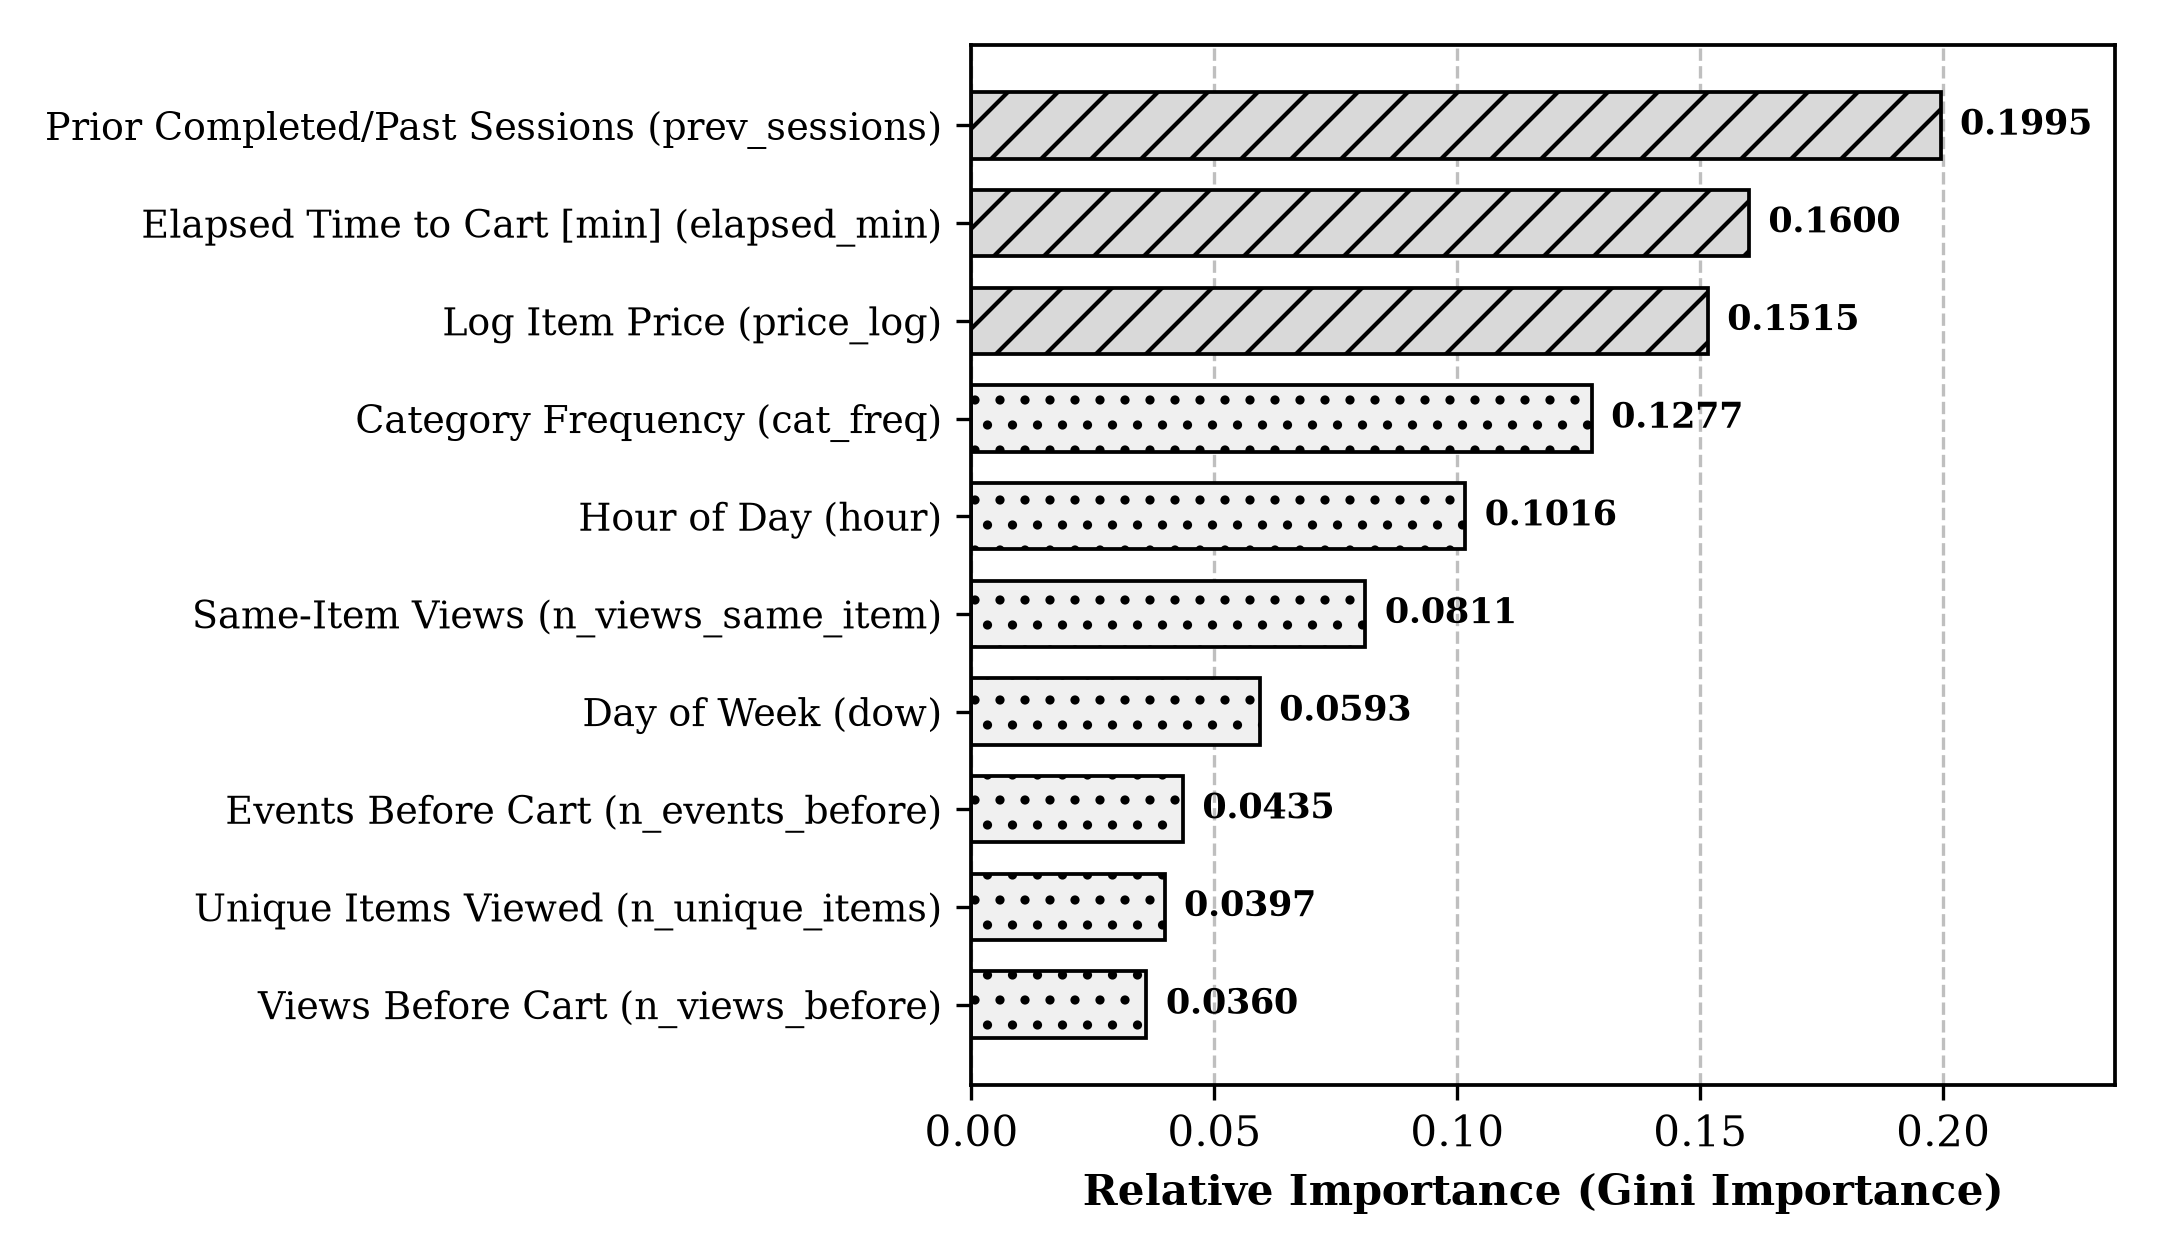

In [5]:
Xtr, ytr = train[FEATURES], train["abandoned"]
Xte, yte = test[FEATURES], test["abandoned"]

rf = RandomForestClassifier(
    n_estimators=200, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=42
)
lr = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
)

rows = []
sens_rows = []
for name, mdl in [("Random Forest", rf), ("Logistic Regression", lr)]:
    t0 = time.time(); mdl.fit(Xtr, ytr); train_t = time.time() - t0
    t0 = time.time(); proba = mdl.predict_proba(Xte)[:, 1]; infer_t = time.time() - t0
    pred = (proba >= 0.5).astype(int)
    rows.append({
        "model": name,
        "precision": precision_score(yte, pred),
        "recall": recall_score(yte, pred),
        "f1": f1_score(yte, pred),
        "roc_auc": roc_auc_score(yte, proba),
        "pr_auc": average_precision_score(yte, proba),
        "balanced_acc": balanced_accuracy_score(yte, pred),
        "train_s": train_t,
        "infer_ms_per_row": infer_t / len(Xte) * 1000
    })
    for tau in [0.30, 0.40, 0.50, 0.60, 0.70]:
        p_tau = (proba >= tau).astype(int)
        sens_rows.append({
            "model": name, "threshold": tau,
            "precision": precision_score(yte, p_tau, zero_division=0),
            "recall": recall_score(yte, p_tau, zero_division=0),
            "f1": f1_score(yte, p_tau, zero_division=0),
            "balanced_acc": balanced_accuracy_score(yte, p_tau)
        })

results = pd.DataFrame(rows).round(4)
print("=== PERBANDINGAN MODEL KLASIFIKASI (THRESHOLD = 0.50) ===")
print(results.to_string(index=False))

print("\n=== ANALISIS SENSITIVITAS THRESHOLD PROBABILITAS ===")
print(pd.DataFrame(sens_rows).round(4).to_string(index=False))

# Visualisasi Feature Importance Random Forest
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
print("\n=== GINI FEATURE IMPORTANCE (RANDOM FOREST) ===")
print(imp.sort_values(ascending=False).round(4))

### Tahap 6: Analisis Pola Waktu (*Abandonment Rate* per Jam dan Hari)

Abandonment Rate tertinggi per Jam (UTC):
hour
9     85.84
12    85.09
11    84.34
8     83.78
10    82.79
Name: abandoned, dtype: float64

Abandonment Rate per Hari (0=Senin s.d. 6=Minggu):
dow
0    71.05
1    71.07
2    69.88
3    73.01
4    74.10
5    77.39
6    76.55
Name: abandoned, dtype: float64


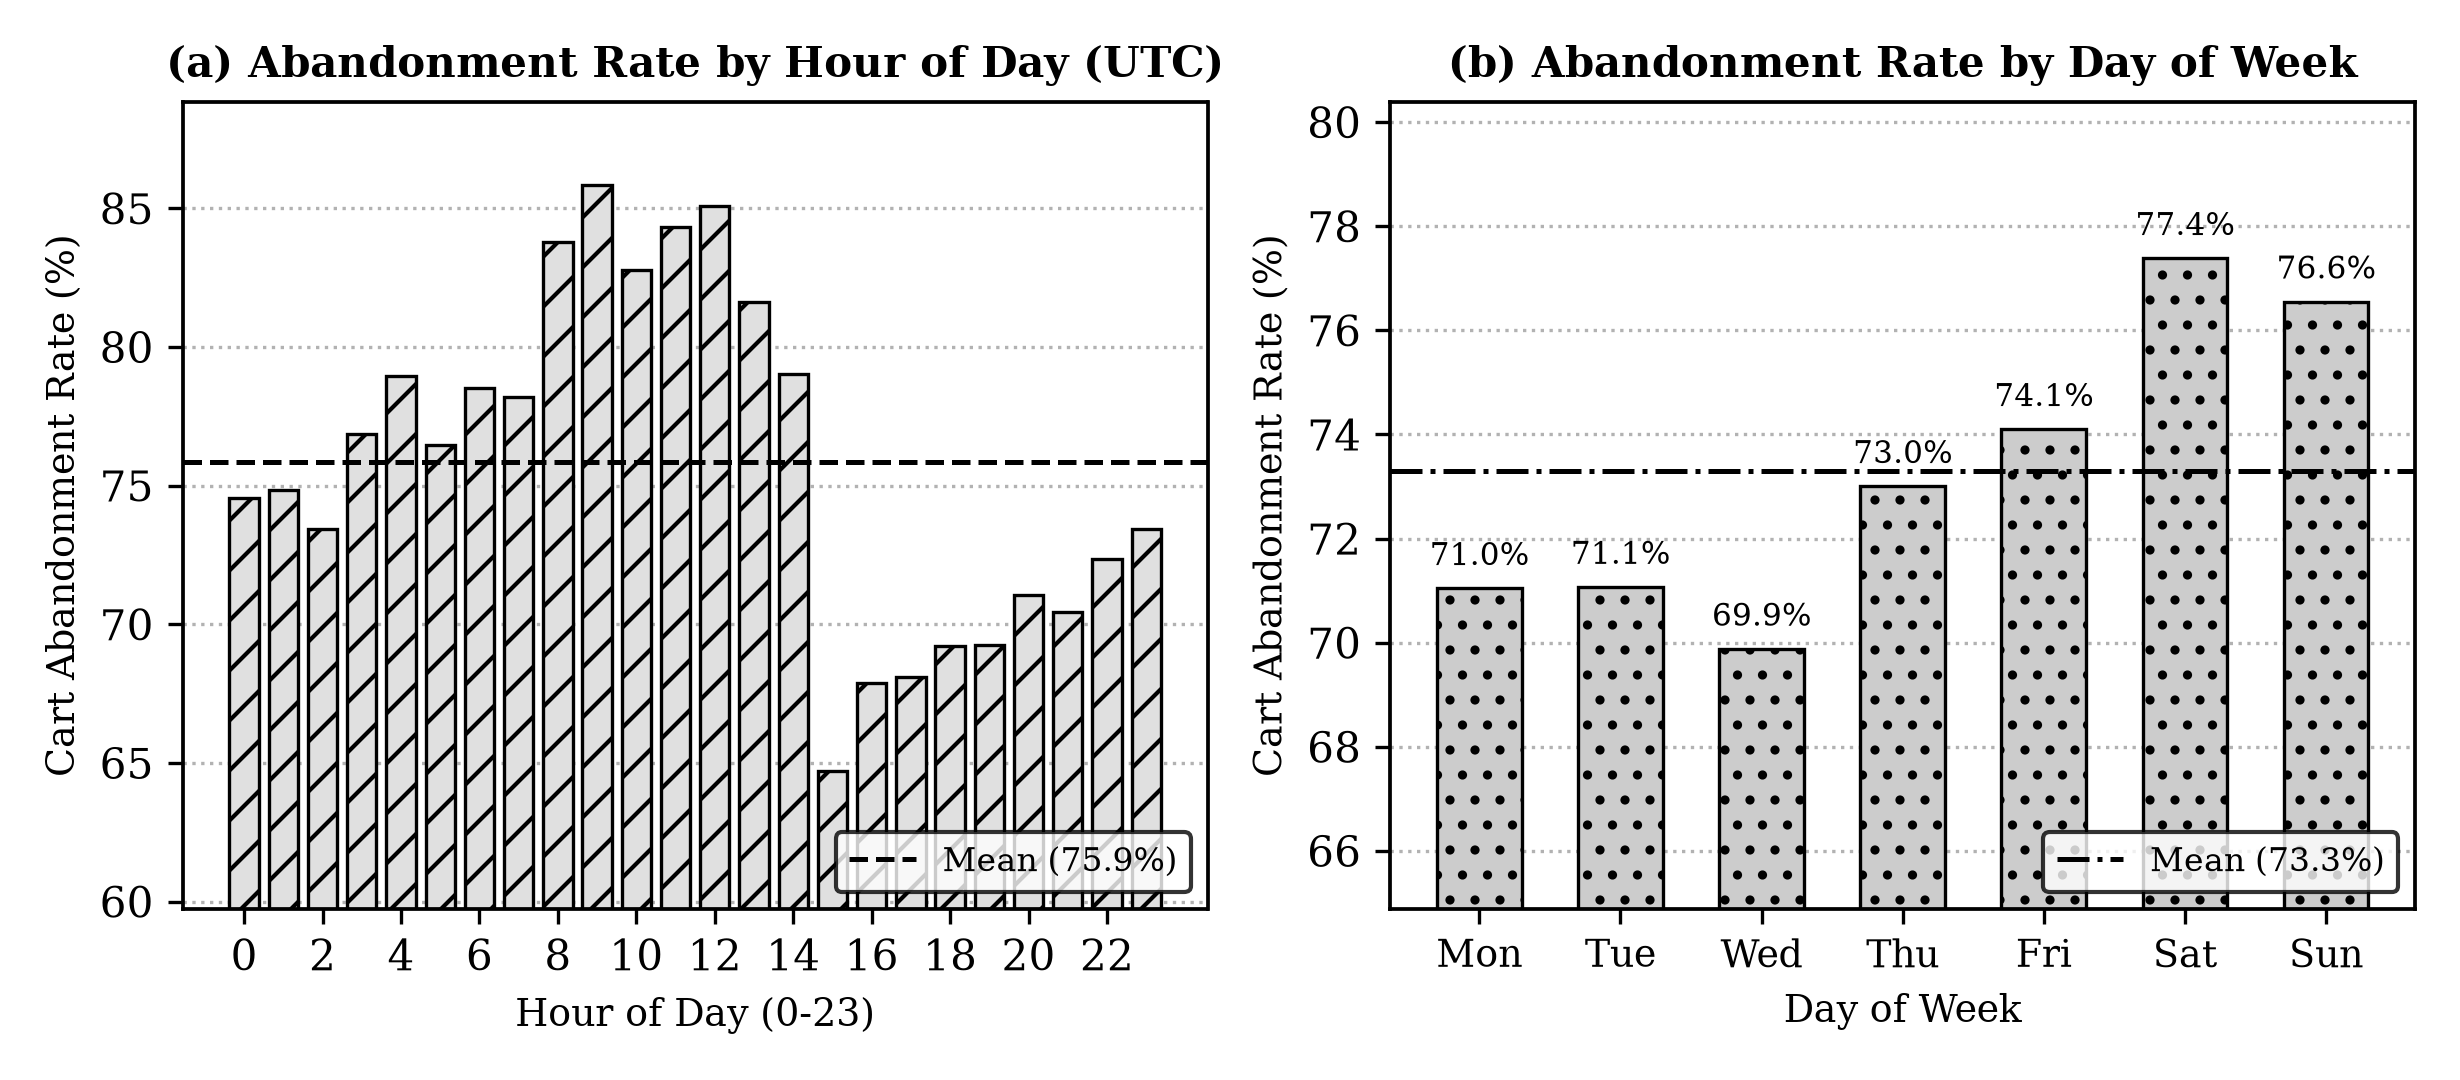

In [6]:
by_hour = (full_df.groupby("hour")["abandoned"].mean() * 100).round(2)
by_dow  = (full_df.groupby("dow")["abandoned"].mean() * 100).round(2)

print("Abandonment Rate tertinggi per Jam (UTC):")
print(by_hour.sort_values(ascending=False).head(5))
print("\nAbandonment Rate per Hari (0=Senin s.d. 6=Minggu):")
print(by_dow)

### Tahap 7: Simulasi Latensi Arsitektur *Batch* vs. *Near Real-Time* (*Effective Recall*)
Mengevaluasi dampak ukuran jendela pemrosesan $W \in \{86.400, 3.600, 300, 60, 10\}$ detik terhadap proporsi *True Positive* yang keputusannya keluar sebelum batas waktu intervensi sesi berakhir ($t_{\text{deadline}} = t_{\text{end}} + 1.800\text{ detik}$):
$$\text{Effective Recall} = \frac{\sum \mathbb{I}(y_i = 1 \land \hat{y}_i = 1 \land t_{\text{decision}, i} \le t_{\text{deadline}, i})}{\sum \mathbb{I}(y_i = 1)}$$

mode  window_s  mean_latency_s  median_latency_s  pct_decided_before_deadline  tp_on_time  effective_recall
    Batch Harian (24 Jam)     86400      37343.6235           26765.0                       3.5970         113            0.0176
    Batch Per Jam (1 Jam)      3600       1792.3429            1788.0                      60.4667        2512            0.3909
    Micro-Batch (5 Menit)       300        150.2142             149.0                     100.0000        4560            0.7095
 Near Real-Time (1 Menit)        60         30.5147              30.0                     100.0000        4560            0.7095
Near Real-Time (10 Detik)        10          5.5187               5.0                     100.0000        4560            0.7095


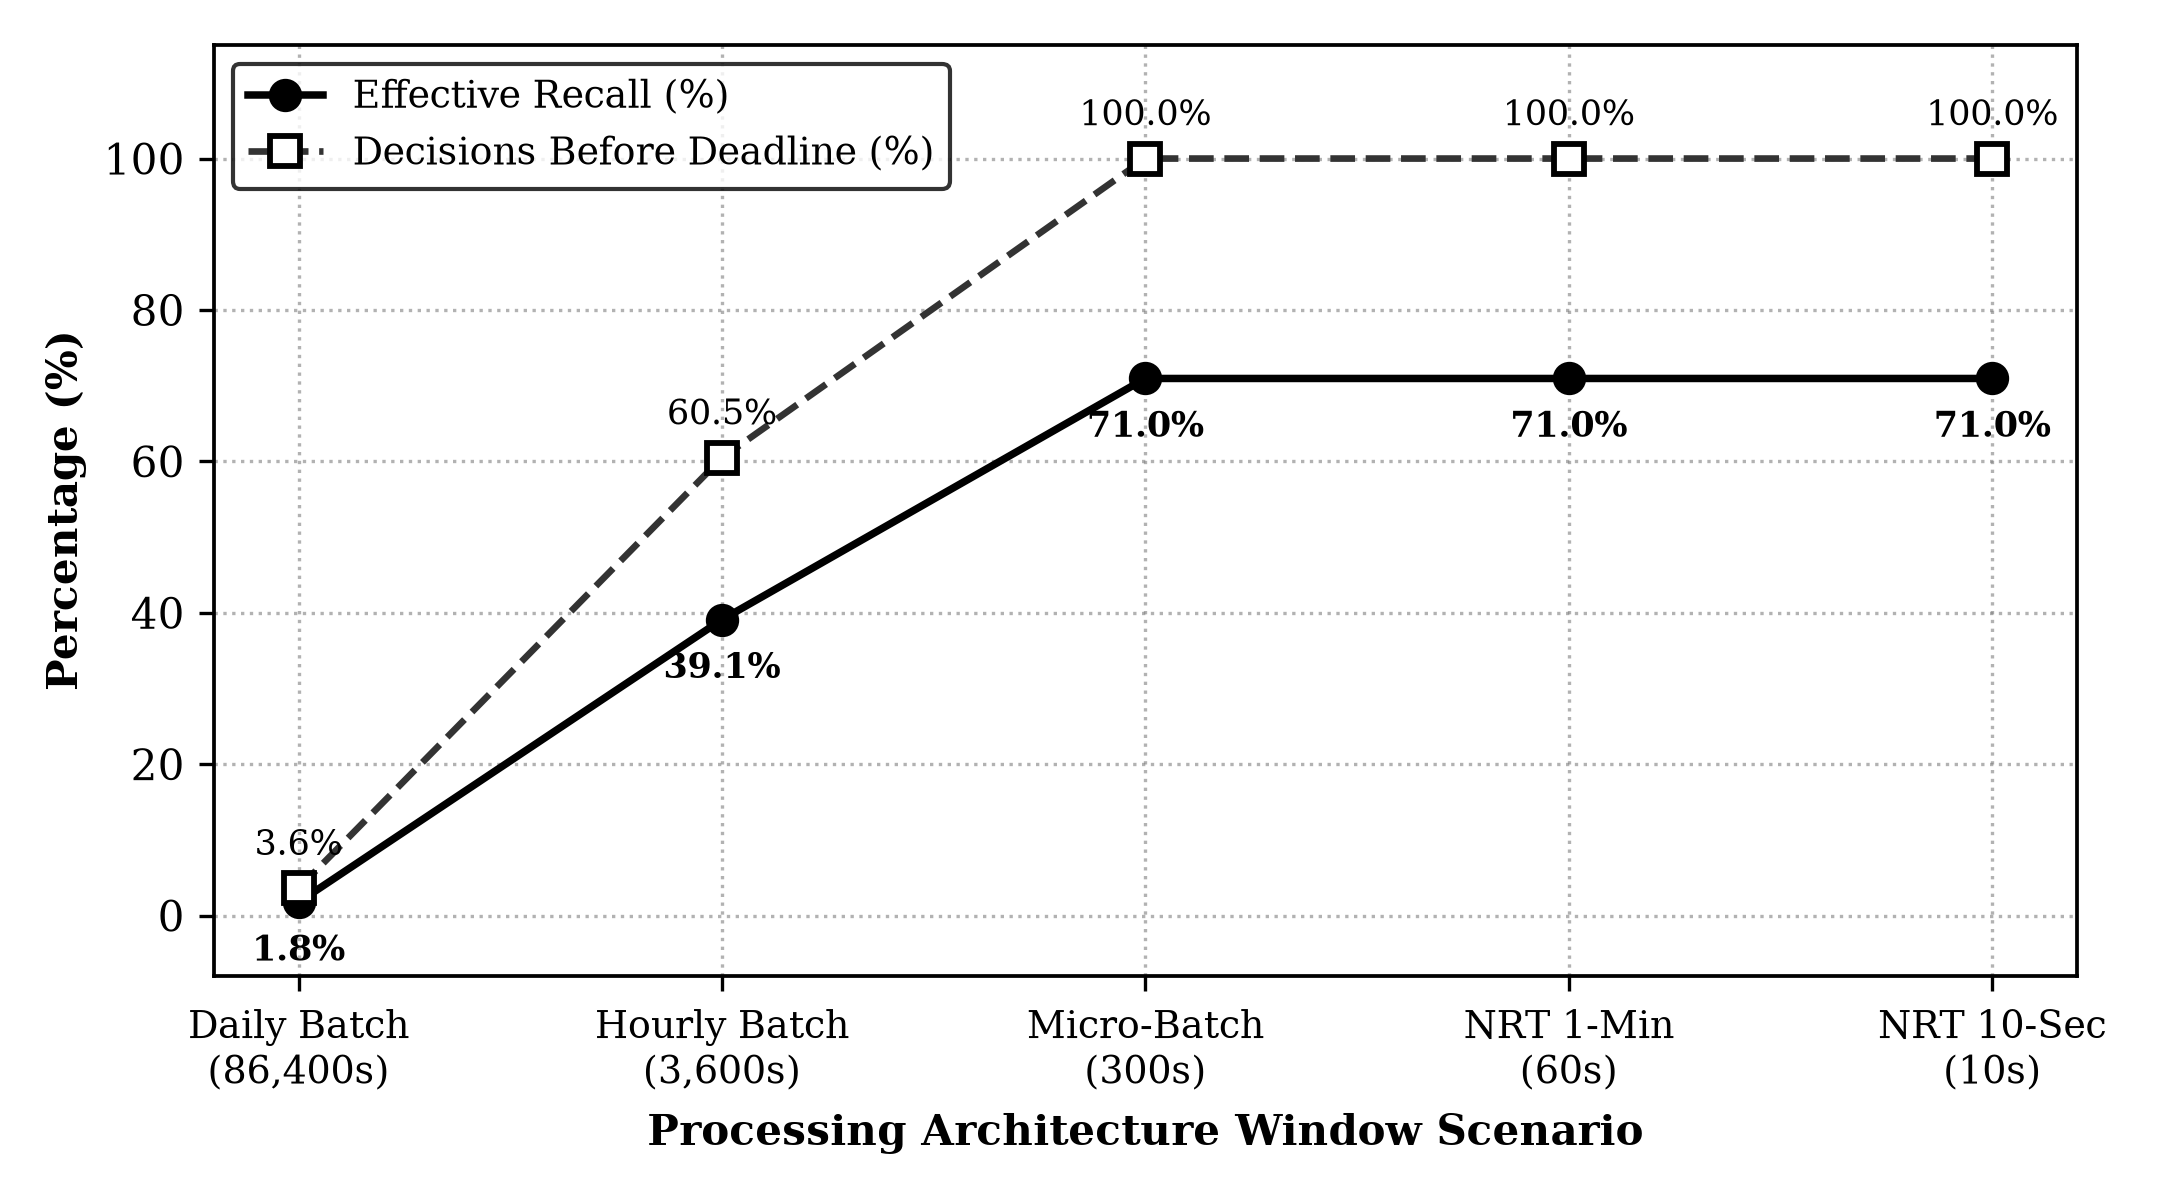

In [7]:
proba_te = rf.predict_proba(Xte)[:, 1]
pred_te = (proba_te >= 0.5).astype(int)
infer_s = results.loc[results.model == "Random Forest", "infer_ms_per_row"].iloc[0] / 1000.0

def simulate(window_s, label):
    decision_ts = (np.floor(test["cart_ts"] / window_s) + 1) * window_s + infer_s
    latency = decision_ts - test["cart_ts"]
    deadline = test["end_ts"] + GAP
    reachable = decision_ts <= deadline
    true_abandon = (test["abandoned"] == 1)
    hit = (pred_te == 1) & true_abandon
    return {
        "mode": label,
        "window_s": window_s,
        "mean_latency_s": latency.mean(),
        "median_latency_s": latency.median(),
        "pct_decided_before_deadline": reachable.mean() * 100,
        "tp_on_time": int((hit & reachable).sum()),
        "effective_recall": ((hit & reachable).sum() / true_abandon.sum())
    }

sim = pd.DataFrame([
    simulate(86400, "Batch Harian (24 Jam)"),
    simulate(3600,  "Batch Per Jam (1 Jam)"),
    simulate(300,   "Micro-Batch (5 Menit)"),
    simulate(60,    "Near Real-Time (1 Menit)"),
    simulate(10,    "Near Real-Time (10 Detik)"),
]).round(4)
print(sim.to_string(index=False))

### Tahap 8: Implementasi *Speed Layer* dengan *PySpark Structured Streaming* (Trigger 2 Detik)
Menguji pemrosesan aliran data *near real-time* secara langsung menggunakan `spark.readStream` dan `writeStream.foreachBatch` dengan interval *trigger* 2 detik. Thread *producer* mengirimkan 1.000 sesi uji dalam 10 berkas *chunk* CSV (masing-masing 100 baris) melalui operasi *atomic rename* (`os.replace`) agar *stream reader* tidak membaca berkas yang belum selesai ditulis.

In [8]:
STREAM_DIR = "/content/stream_in" if os.path.exists("/content") else os.path.join(os.getcwd(), "stream_in")
TMP_DIR    = "/content/stream_tmp" if os.path.exists("/content") else os.path.join(os.getcwd(), "stream_tmp")
for d in (STREAM_DIR, TMP_DIR):
    shutil.rmtree(d, ignore_errors=True)
    os.makedirs(d, exist_ok=True)

schema = StructType([StructField(c, DoubleType()) for c in FEATURES + ["write_ts"]])
lat_log = []

def process_batch(df, batch_id):
    if df.rdd.isEmpty():
        return
    pdf = df.toPandas()
    proba = rf.predict_proba(pdf[FEATURES])[:, 1]
    now = time.time()
    lat_log.append(pd.DataFrame({
        "batch_id": batch_id,
        "latency_s": now - pdf["write_ts"],
        "pred": (proba >= 0.5).astype(int)
    }))

def producer(n_files=10, rows=100, delay=1.2):
    sample = test.sample(n_files * rows, random_state=42)[FEATURES].astype(float).reset_index(drop=True)
    for i in range(n_files):
        chunk = sample.iloc[i * rows:(i + 1) * rows].copy()
        chunk["write_ts"] = time.time()
        tmp_path = os.path.join(TMP_DIR, f"chunk_{i:02d}.csv")
        dst_path = os.path.join(STREAM_DIR, f"chunk_{i:02d}.csv")
        chunk.to_csv(tmp_path, index=False)
        os.replace(tmp_path, dst_path)  # Atomic rename
        time.sleep(delay)

query = (
    spark.readStream
    .schema(schema)
    .option("header", "true")
    .csv(STREAM_DIR)
    .writeStream
    .foreachBatch(process_batch)
    .trigger(processingTime="2 seconds")
    .start()
)

th = threading.Thread(target=producer, daemon=True)
th.start()
th.join()
time.sleep(4)
query.stop()

stream_lat = pd.concat(lat_log, ignore_index=True)
print("=== DISTRIBUSI LATENSI END-TO-END PYSPARK STRUCTURED STREAMING ===")
print(stream_lat["latency_s"].describe().round(4))

=== DISTRIBUSI LATENSI END-TO-END PYSPARK STRUCTURED STREAMING ===
count    1000.0000
mean        1.2735
std         0.6053
min         0.4980
25%         0.5571
50%         1.2596
75%         2.0006
max         2.0766
Name: latency_s, dtype: float64
